# Phase 4 - Product Demand Forecasting
**XGBoost time series** (compared with Random Forest)

### What this notebook does
Predicts how many units of a product a store will sell over the next 30 days. It powers the
admin dashboard's forecast chart.

### Pipeline
1. Load 913,000 daily sales rows (10 stores x 50 items x 5 years)
2. Engineer **date features** + **lag features** (t-1, t-7, t-14) + **rolling means** (7, 30 days)
3. **Time-based split** - train on the past, validate on the **last 90 days** (no shuffling!)
4. Compare **Random Forest** vs **XGBoost**, keep the lower RMSE
5. Forecast **recursively** - each predicted day feeds the next day's lags

### About the dates (important)
- `train.csv` covers **2013-01-01 to 2017-12-31**.
- `test.csv` is the Kaggle competition's **2018-01-01 to 2018-03-31** target window.
- So if you see **2018**, it is the *test file's* window from the original public dataset -
  not a date produced by our model. The model forecasts forward from the last training day.

> **Why time-based split?** A random split would leak future days into the training set and give
> unrealistically good scores. For forecasting, the validation period must come *after* training.


In [1]:
#@title 0  Install dependencies { display-mode: "form" }
!pip -q install pandas numpy scikit-learn xgboost matplotlib
print("deps ready")


deps ready


## 1. Load the data


In [2]:
#@title 1.1  Load the dataset (Colab-ready) { display-mode: "form" }
import os

CSV_NAME = "train.csv"
LOCAL_PATH = "data/raw/demand/train.csv"   # used if you cloned the repo into Colab

PATH = None

# (a) already in the Colab working dir?
if os.path.exists(CSV_NAME):
    PATH = CSV_NAME
# (b) repo layout present?
elif os.path.exists(LOCAL_PATH):
    PATH = LOCAL_PATH

# (c) otherwise upload it (Colab file picker)
if PATH is None:
    try:
        from google.colab import files
        print('Please upload:', CSV_NAME)
        up = files.upload()
        PATH = list(up.keys())[0]
    except Exception:
        raise FileNotFoundError(
            'Dataset not found. Put ' + CSV_NAME + ' next to this notebook, or mount Drive.'
        )

print('Using dataset:', PATH)


Please upload: train.csv


Saving train.csv to train.csv
Using dataset: train.csv


In [3]:
#@title 1.2  Load sales + date features { display-mode: "form" }
import pandas as pd, numpy as np

df = pd.read_csv(PATH, parse_dates=["date"])
print(f"rows: {len(df):,} | stores: {df['store'].nunique()} | items: {df['item'].nunique()}")
print(f"date range: {df['date'].min().date()} -> {df['date'].max().date()}")
df.head()


rows: 913,000 | stores: 10 | items: 50
date range: 2013-01-01 -> 2017-12-31


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [4]:
# date calendar features
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)
df["year"]       = df["date"].dt.year
df["month"]      = df["date"].dt.month
df["day"]        = df["date"].dt.day
df["dayofweek"]  = df["date"].dt.dayofweek
df["weekofyear"] = df["date"].dt.isocalendar().week.astype(int)
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
df["store_id"]   = df["store"].astype("category").cat.codes
df["item_id"]    = df["item"].astype("category").cat.codes
print("calendar features added")


calendar features added


## 2. Lag + rolling features
These capture **trend** and **weekly seasonality**. All computed *per store-item* in date order,
and shifted by 1 so a row never sees its own value (no leakage).


In [5]:
#@title 2.1  Build lag/rolling features { display-mode: "form" }
g = df.groupby(["store", "item"])["sales"]
df["lag1"]   = g.shift(1)
df["lag7"]   = g.shift(7)
df["lag14"]  = g.shift(14)
df["roll7"]  = g.transform(lambda s: s.shift(1).rolling(7).mean())
df["roll30"] = g.transform(lambda s: s.shift(1).rolling(30).mean())

FEATURES = ["year", "month", "day", "dayofweek", "weekofyear", "is_weekend",
            "store_id", "item_id", "lag1", "lag7", "lag14", "roll7", "roll30"]
df = df.dropna(subset=FEATURES + ["sales"]).reset_index(drop=True)
print(f"modelling rows: {len(df):,}")


modelling rows: 898,000


## 3. Time-based split (last 90 days = validation)


In [6]:
#@title 3.1  Time-based split { display-mode: "form" }
VAL_DAYS = 90
cutoff = df["date"].max() - pd.Timedelta(days=VAL_DAYS)
train = df[df["date"] < cutoff]
val   = df[df["date"] >= cutoff]
Xtr, ytr = train[FEATURES], train["sales"]
Xva, yva = val[FEATURES],   val["sales"]
print(f"train rows: {len(train):,} | val rows: {len(val):,}")
print(f"train: {train['date'].min().date()} -> {train['date'].max().date()}")
print(f"val  : {val['date'].min().date()} -> {val['date'].max().date()}")


train rows: 852,500 | val rows: 45,500
train: 2013-01-31 -> 2017-10-01
val  : 2017-10-02 -> 2017-12-31


## 4. Train + compare RF vs XGBoost


In [7]:
#@title 4.1  Train both models { display-mode: "form" }
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb

def evaluate(model, X, y):
    p = model.predict(X)
    return mean_absolute_error(y, p), mean_squared_error(y, p) ** 0.5

rf = RandomForestRegressor(n_estimators=120, n_jobs=-1, random_state=42)
rf.fit(Xtr, ytr)
mae_rf, rmse_rf = evaluate(rf, Xva, yva)

xgbm = xgb.XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                        n_jobs=-1, random_state=42)
xgbm.fit(Xtr, ytr)
mae_x, rmse_x = evaluate(xgbm, Xva, yva)

res = pd.DataFrame({"MAE": [mae_rf, mae_x], "RMSE": [rmse_rf, rmse_x]},
                   index=["Random Forest", "XGBoost"])
res


,MAE,RMSE
Random Forest,6.196173,8.087867
XGBoost,5.927607,7.677663


## 5. Winner + feature importance


WINNER: XGBoost  (MAE=5.928, RMSE=7.678)


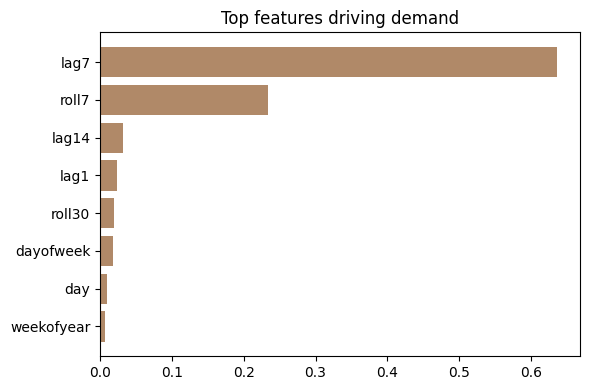

In [9]:
#@title 5.1  Pick winner, plot importance { display-mode: "form" }
winner_name, winner, w_mae, w_rmse = (
    ("XGBoost", xgbm, mae_x, rmse_x) if rmse_x <= rmse_rf else
    ("Random Forest", rf, mae_rf, rmse_rf))
print(f"WINNER: {winner_name}  (MAE={w_mae:.3f}, RMSE={w_rmse:.3f})")

imp = sorted(zip(FEATURES, rf.feature_importances_), key=lambda x: -x[1])[:8]
import matplotlib.pyplot as plt
names = [f for f, _ in imp][::-1]
scores = [s for _, s in imp][::-1]
plt.figure(figsize=(6, 4))
plt.barh(names, scores, color="#b08968")
plt.title("Top features driving demand"); plt.tight_layout(); plt.show()


### Interpretation
The **lag and rolling features** dominate importance - i.e. recent sales history is the
strongest predictor of near-future demand (autocorrelation). Calendar features add the weekly
and yearly seasonality on top.


## 6. Actual vs predicted (validation window)


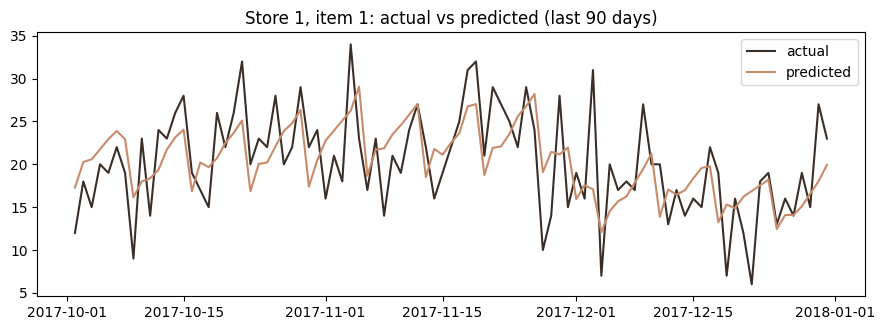

In [10]:
#@title 6.1  Plot a sample store-item forecast vs actual { display-mode: "form" }
s, it = 1, 1
sub = val[(val["store"] == s) & (val["item"] == it)].sort_values("date")
pred = winner.predict(sub[FEATURES])
plt.figure(figsize=(9, 3.4))
plt.plot(sub["date"], sub["sales"], label="actual", color="#3a2e26")
plt.plot(sub["date"], pred, label="predicted", color="#c98a6a")
plt.title(f"Store {s}, item {it}: actual vs predicted (last 90 days)")
plt.legend(); plt.tight_layout(); plt.show()


## 7. Recursive 30-day forecast (what the app serves)
The app starts from the last known 30 days and predicts forward one day at a time, feeding
each prediction back as the next day's lag.


Store 1, item 1 -> next 30 days predicted demand = 478 units


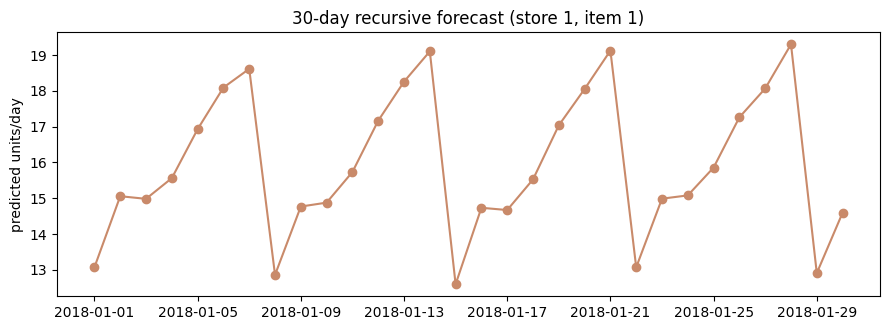

In [11]:
#@title 7.1  Refit on all data + recursive forecast { display-mode: "form" }
winner.fit(df[FEATURES], df["sales"])

history = {}
for (st, itm), sb in df.sort_values("date").groupby(["store", "item"]):
    history[(int(st), int(itm))] = {"sales": sb["sales"].tail(30).tolist(),
                                    "last_date": sb["date"].max()}

def forecast(store, item, horizon=30):
    h = list(history[(store, item)]["sales"])
    cur = pd.Timestamp(history[(store, item)]["last_date"]) + pd.Timedelta(days=1)
    out = []
    for _ in range(horizon):
        feat = {
            "year": cur.year, "month": cur.month, "day": cur.day,
            "dayofweek": cur.dayofweek, "weekofyear": cur.isocalendar().week,
            "is_weekend": int(cur.dayofweek >= 5),
            "store_id": int(df[df.store == store].store_id.iloc[0]),
            "item_id":  int(df[df.item == item].item_id.iloc[0]),
            "lag1": h[-1], "lag7": h[-7], "lag14": h[-14],
            "roll7": float(np.mean(h[-7:])), "roll30": float(np.mean(h[-30:])),
        }
        p = max(float(winner.predict(pd.DataFrame([feat])[FEATURES])[0]), 0.0)
        out.append((cur, p)); h.append(p); h = h[-30:]
        cur += pd.Timedelta(days=1)
    return out

fc = forecast(1, 1, 30)
tot = sum(v for _, v in fc)
print(f"Store 1, item 1 -> next 30 days predicted demand = {tot:.0f} units")

plt.figure(figsize=(9, 3.4))
plt.plot([d for d, _ in fc], [v for _, v in fc], marker="o", color="#c98a6a")
plt.title("30-day recursive forecast (store 1, item 1)")
plt.ylabel("predicted units/day"); plt.tight_layout(); plt.show()


## 8. Save model


---
## Save the trained model

The service expects a pickled bundle in `fastapi_ml/models/`. In Colab we save it to `/content/models/`
and offer a download so you can drop it into the repo.


In [12]:
#@title 8.1  Save bundle { display-mode: "form" }
import pickle, os

bb = {
    "model_type": "xgboost" if winner_name == "XGBoost" else "random_forest",
    "model": winner,
    "features": FEATURES,
    "history": history,
    "metrics": {"mae": float(w_mae), "rmse": float(w_rmse)},
}
os.makedirs("/content/models", exist_ok=True)
OUT = "/content/models/demand_model.pkl"
with open(OUT, "wb") as f:
    pickle.dump(bb, f)
print("saved ->", OUT)

try:
    from google.colab import files
    files.download(OUT)
except Exception as e:
    print("Not in Colab, skipping download.", e)


saved -> /content/models/demand_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>